In [61]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib.gridspec import GridSpec
import seaborn as sns
from scipy.ndimage import gaussian_filter1d
from load_traces import load_aligned_act, build_intervals
import os

matplotlib.style.use('paper_style.mplstyle')

In [62]:
# ── Parameters — edit these ───────────────────────────────────────────────────
animal  = 'C3M4'
session = 'R1'

pre_sec    = 30
post_sec   = 120
n_points   = 2000
sort_window = (0, 30)   # seconds post-onset used to rank cells
sigma      = 4          # gaussian smoothing (frames); set 0 to skip

base_dir     = os.getcwd()
traces_dir   = f'{base_dir}/Traces'
behavior_csv = f'{base_dir}/data/intervals_allmice.csv'
info_csv     = f'{base_dir}/dbnst_data_info.csv'

color_map = {
    'Aggressive':       '#fe0806',
    'Pro-Social':       '#55a0fb',
    'Social Avoidance': '#b856d7',
    'Asocial':          '#e7e6e6',
}

In [63]:
# ── Load data ─────────────────────────────────────────────────────────────────
act_full  = load_aligned_act(animal, session, traces_dir, behavior_csv, info_csv)
intervals = build_intervals(animal, session, behavior_csv)

# flatten index to seconds
act = act_full.loc[(animal, session)].copy()
act.index = act.index.total_seconds()

cell_cols = [c for c in act.columns if str(c).isdigit() or isinstance(c, (int, np.integer))]
print(f'{animal} {session} — {len(cell_cols)} cells')

C3M4 R1 — 46 cells


In [64]:
# ── Smooth & extract window around first Pro-Social onset ─────────────────────
if sigma > 0:
    act[cell_cols] = gaussian_filter1d(act[cell_cols].to_numpy(), sigma=sigma, axis=0)

prosocial = intervals[intervals['behavior_type'] == 'Pro-Social'].sort_values('start')
onset = prosocial.iloc[0]['start']

t_start = onset - pre_sec
t_end   = onset + post_sec
win     = act[(act.index >= t_start) & (act.index < t_end)][cell_cols]
t_rel   = win.index.to_numpy() - onset

# interpolate all cells onto common time axis
t_common = np.linspace(-pre_sec, post_sec, n_points)
mat = np.vstack([np.interp(t_common, t_rel, win.values[:, i]) for i in range(len(cell_cols))])
# mat shape: (n_cells, n_points)

# sort by mean activity in sort_window
sort_mask  = (t_common >= sort_window[0]) & (t_common <= sort_window[1])
sort_order = np.argsort(mat[:, sort_mask].mean(axis=1))[::-1]
sorted_mat = mat[sort_order]

/var/folders/4k/5kmnnrq94j136038_jy_4twc0000gq/T/ipykernel_61251/2196216781.py:60: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


Saved to figures/C3M4_R1_all_cells_heatmap.pdf


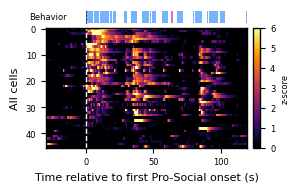

In [66]:
# ── Plot ──────────────────────────────────────────────────────────────────────
from matplotlib.backends.backend_pdf import PdfPages

ivs_rel = intervals.copy()
ivs_rel['start_rel'] = ivs_rel['start'] - onset
ivs_rel['end_rel']   = ivs_rel['end']   - onset
ivs_window = ivs_rel[
    (ivs_rel['end_rel']   > -pre_sec) &
    (ivs_rel['start_rel'] < post_sec) &
    (ivs_rel['behavior_type'].isin(color_map))
]

fig, (ax_beh, ax_heat) = plt.subplots(
    2, 1, figsize=(2.6,1.8),
    gridspec_kw={'height_ratios': [1, 8], 'hspace': 0.05},
    sharex=True,
)

# heatmap
im = ax_heat.imshow(
    sorted_mat,
    aspect='auto',
    interpolation='nearest',
    vmin=0, vmax=6,
    extent=[-pre_sec, post_sec, sorted_mat.shape[0] - 0.5, -0.5],
    cmap='inferno',
)
ax_heat.set_xlim(-pre_sec, post_sec)

ax_heat.axvline(0, color='white', linewidth=1, linestyle='--')
ax_heat.set_xlabel('Time relative to first Pro-Social onset (s)', size=8)
ax_heat.set_ylabel('All cells', size=8)
ax_heat.tick_params(axis='x', labelsize=6)
ax_heat.tick_params(axis='y', labelsize=6)

# behavior raster
seen = set()
for _, row in ivs_window.iterrows():
    bt = row['behavior_type']
    ax_beh.barh(y=0, width=row['end_rel'] - row['start_rel'], left=row['start_rel'],
                height=0.8, color=color_map[bt],
                label=bt if bt not in seen else '', alpha=0.8)
    seen.add(bt)
ax_beh.axvline(0, color='black', linewidth=0.5, linestyle='--')
ax_beh.set_ylim([-0.5, 0.5])
ax_beh.set_yticks([])
ax_beh.tick_params(axis='x', which='both', bottom=False, labelbottom=False)
ax_beh.set_ylabel('Behavior', fontsize=6, rotation=0, labelpad=-5, va='center')
ax_beh.spines[['top', 'right', 'left', 'bottom']].set_visible(False)
#ax_beh.legend(frameon=False, bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=6)

# add colorbar after tight_layout so it doesn't affect axis widths
cbar_ax = fig.add_axes([ax_heat.get_position().x1 + 0.02,
                         ax_heat.get_position().y0,
                         0.03,
                         ax_heat.get_position().height])
cbar = fig.colorbar(im, cax=cbar_ax)
cbar.set_label('z-score', fontsize=6)
cbar.ax.tick_params(labelsize=6)
plt.tight_layout()

out_path = f'figures/{animal}_{session}_all_cells_heatmap.pdf'
with PdfPages(out_path) as pdf:
    pdf.savefig(fig, bbox_inches='tight')
print(f'Saved to {out_path}')


In [ ]:
# ── Build mixed-tuned cell dict ───────────────────────────────────────────────
from load_traces import get_tuned_df
from itertools import product as iproduct
from scipy.ndimage import gaussian_filter1d
import matplotlib.patches as mpatches

data_dir = f'{base_dir}/data'
all_animals = pd.read_csv(info_csv)['Mouse'].unique()
tuned_ids, tuned_df = get_tuned_df(all_animals, data_dir)

# for each (animal, session), find cells tuned to >1 behavior type
mixed_cells = {}
for (ani, ses), grp in tuned_ids.groupby(['animal', 'session']):
    cell_to_btypes = {}
    for _, row in grp.iterrows():
        for cell in row['tuned_cells']:
            cell_to_btypes.setdefault(cell, set()).add(row['behavior_type'])
    mixed = [c for c, btypes in cell_to_btypes.items() if len(btypes) > 1]
    if mixed:
        mixed_cells[(ani, ses)] = mixed

# show summary
for k, v in mixed_cells.items():
    print(f'{k}: {len(v)} mixed cells — {v}')


In [ ]:
# ── Plot mixed-tuned cell traces ──────────────────────────────────────────────
BEHAVIOR_COLORS = {
    'Aggressive':       '#fe0806',
    'Pro-Social':       '#55a0fb',
    'Social Avoidance': '#b856d7',
    'Baseline':         'gray',
}
WINDOW_PAD = 90  # seconds either side of all behavior bouts

session_cache = {}

for (ani, ses), cells in mixed_cells.items():
    if not cells:
        continue

    key = (ani, ses)
    if key not in session_cache:
        session_cache[key] = load_aligned_act(ani, ses, traces_dir, behavior_csv, info_csv)
    act = session_cache[key]

    n = len(cells)
    fig, axes = plt.subplots(n, 1, figsize=(4, 0.5 * n),
                             sharex=True, sharey=False, squeeze=False)
    fig.subplots_adjust(hspace=0.05)

    t_starts, t_ends = [], []

    for i, cell in enumerate(cells):
        ax = axes[i][0]

        full_trace = act[cell]
        time = full_trace.index.get_level_values('timestamp').total_seconds()
        smoothed = gaussian_filter1d(full_trace.values.astype(float), sigma=3)
        s_min, s_max = smoothed.min(), smoothed.max()
        smoothed_norm = (smoothed - s_min) / (s_max - s_min) if s_max > s_min else np.zeros_like(smoothed)

        # window: all social bouts ± pad
        social = act[act['behavior_type'].isin(['Pro-Social', 'Social Avoidance', 'Aggressive'])]
        if not social.empty:
            bout_times = social.index.get_level_values('timestamp').total_seconds()
            t_start = max(time[0], bout_times.min() - WINDOW_PAD)
            t_end   = min(time[-1], bout_times.max() + WINDOW_PAD)
        else:
            t_start, t_end = time[0], time[-1]
        t_starts.append(t_start)
        t_ends.append(t_end)

        mask = (time >= t_start) & (time <= t_end)
        ax.plot(time[mask], smoothed_norm[mask], lw=0.4, color='k')

        for beh, color in BEHAVIOR_COLORS.items():
            beh_rows = act[act['behavior_type'] == beh]
            if beh_rows.empty:
                continue
            in_beh = beh_rows.index.get_level_values('timestamp').total_seconds()
            in_beh = in_beh[(in_beh >= t_start) & (in_beh <= t_end)]
            if len(in_beh) == 0:
                continue
            breaks = np.where(np.diff(in_beh) > 0.1)[0] + 1
            for chunk in np.split(in_beh, breaks):
                ax.axvspan(chunk[0], chunk[-1], alpha=0.25, color=color, lw=0)

        # label which behaviors this cell is tuned to
        cell_btypes = sorted(
            row['behavior_type']
            for _, row in tuned_ids[
                (tuned_ids['animal'] == ani) & (tuned_ids['session'] == ses)
            ].iterrows()
            if cell in row['tuned_cells']
        )
        ax.set_ylabel(f'c{cell}\n{"/".join([b[:3] for b in cell_btypes])}',
                      fontsize=4, rotation=0, labelpad=40, va='center')
        ax.set_ylim(-0.05, 1.15)
        ax.set_yticks([0, 1])
        ax.set_yticklabels(['0', '1'], fontsize=4)
        ax.tick_params(axis='x', labelsize=5)
        sns.despine(ax=ax, bottom=(i < n - 1))

    axes[0][0].set_xlim(min(t_starts), max(t_ends))

    # scalebar on last axis
    ax_last = axes[-1][0]
    bar_len = 30
    bar_x = max(t_ends) - bar_len - (max(t_ends) - min(t_starts)) * 0.02
    ax_last.plot([bar_x, bar_x + bar_len], [-0.15, -0.15], color='k', lw=1.5,
                 clip_on=False, transform=ax_last.get_xaxis_transform())
    ax_last.text(bar_x + bar_len / 2, -0.28, f'{bar_len} s',
                 ha='center', va='top', fontsize=5,
                 transform=ax_last.get_xaxis_transform())
    ax_last.set_xticks([])

    fig.suptitle(f'{ani} {ses} — mixed-tuned cells (n={n})', fontsize=7)
    plt.tight_layout()
    plt.savefig(f'figures/{ani}_{ses}_mixed_cells.pdf', bbox_inches='tight', transparent=True)
    plt.show()
